In [1]:
import os

import pandas as pd
import numpy as np

from scipy import stats

# from sklearn.datasets import load_boston 
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, \
StratifiedShuffleSplit, GridSearchCV, RandomizedSearchCV

from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet,\
RidgeClassifier, LogisticRegressionCV

from sklearn.metrics import mean_absolute_error, mean_squared_error, f1_score, accuracy_score, \
roc_auc_score, classification_report, r2_score, precision_score, recall_score, \
log_loss, mean_squared_log_error

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

#from sklearn.datasets import make_regression, load_iris

import matplotlib.pyplot as plt
import seaborn as sns
            
from tqdm import tqdm_notebook
from tqdm import tqdm

import warnings
warnings.filterwarnings("ignore")

import ipywidgets

RAND = 10

# 🧪 3. Бейзлайн-модель

Создаём первую модель на логистической регрессии:
- Используем только количественные признаки,
- Применим стандартизацию,
- Оценим по метрике ROC AUC.

In [37]:
df_train = pd.read_csv('df_full.csv')

In [38]:
df_train.shape

(1177, 19931)

In [39]:
df_train[['Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
       'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
       'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
       'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
       'Barratt_Barratt_P2_Occ', 'EHQ_EHQ_Total', 'ColorVision_CV_Score',
       'APQ_P_APQ_P_CP', 'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV',
       'APQ_P_APQ_P_OPD', 'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP',
       'SDQ_SDQ_Conduct_Problems', 'SDQ_SDQ_Difficulties_Total',
       'SDQ_SDQ_Emotional_Problems', 'SDQ_SDQ_Externalizing',
       'SDQ_SDQ_Generating_Impact', 'SDQ_SDQ_Hyperactivity',
       'SDQ_SDQ_Internalizing', 'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial',
       'MRI_Track_Age_at_Scan', 'ADHD_Outcome', 'Sex_F', 'One_parent']] = df_train[['Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
       'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
       'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
       'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
       'Barratt_Barratt_P2_Occ', 'EHQ_EHQ_Total', 'ColorVision_CV_Score',
       'APQ_P_APQ_P_CP', 'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV',
       'APQ_P_APQ_P_OPD', 'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP',
       'SDQ_SDQ_Conduct_Problems', 'SDQ_SDQ_Difficulties_Total',
       'SDQ_SDQ_Emotional_Problems', 'SDQ_SDQ_Externalizing',
       'SDQ_SDQ_Generating_Impact', 'SDQ_SDQ_Hyperactivity',
       'SDQ_SDQ_Internalizing', 'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial',
       'MRI_Track_Age_at_Scan', 'ADHD_Outcome', 'Sex_F', 'One_parent']].astype('category') 


In [40]:
ID_COL = 'participant_id'

CAT_COL = ['Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
       'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
       'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
       'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
       'Barratt_Barratt_P2_Occ', 'EHQ_EHQ_Total', 'ColorVision_CV_Score',
       'APQ_P_APQ_P_CP', 'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV',
       'APQ_P_APQ_P_OPD', 'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP',
       'SDQ_SDQ_Conduct_Problems', 'SDQ_SDQ_Difficulties_Total',
       'SDQ_SDQ_Emotional_Problems', 'SDQ_SDQ_Externalizing',
       'SDQ_SDQ_Generating_Impact', 'SDQ_SDQ_Hyperactivity',
       'SDQ_SDQ_Internalizing', 'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial',
       'MRI_Track_Age_at_Scan'] 
NUM_COL = list(df_train.select_dtypes(include=['float64','int64']))

In [9]:
df_train.head(5)

,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,...,195throw_196thcolumn,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn
0,00aIpNTbG5uh,2019,4,1.0,0.0,3.0,21.0,45.0,-1.0,-1.0,...,-0.047477,-0.096450,-0.280312,0.037560,0.423037,0.242453,0.336213,0.402338,0.327915,0.539032
1,00fV0OyyoLfw,2017,1,0.0,9.0,2.0,21.0,0.0,21.0,45.0,...,-0.143218,-0.276464,-0.332783,-0.332711,0.556939,0.475578,0.429196,0.457970,0.312571,0.595978
2,04X1eiS79T4B,2017,1,1.0,2.0,2.0,9.0,0.0,-1.0,-1.0,...,-0.133778,-0.108588,-0.002132,-0.175586,0.679183,0.290292,0.486680,0.255208,0.575017,0.605182
3,05ocQutkURd6,2018,1,3.0,8.0,2.0,18.0,10.0,18.0,0.0,...,-0.096647,-0.041420,-0.199576,-0.216457,0.519074,0.298586,0.415466,0.511607,0.361204,0.446613
4,06YUNBA9ZRLq,2018,1,0.0,1.0,2.0,12.0,0.0,-1.0,-1.0,...,-0.158995,-0.274017,-0.141012,-0.002865,0.515169,0.336139,0.316430,0.442230,0.177079,0.378278


<Axes: xlabel='ADHD_Outcome', ylabel='count'>

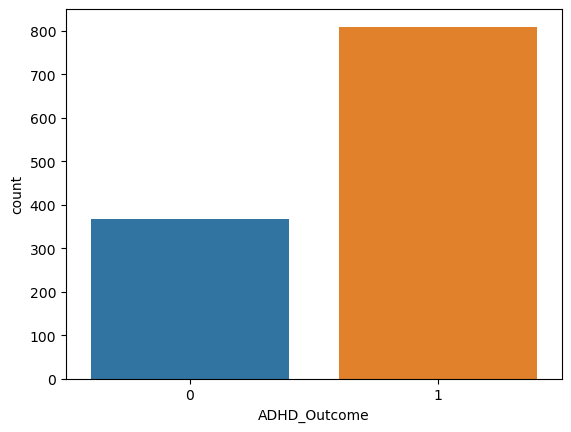

In [41]:
sns.countplot(df_train, x='ADHD_Outcome')

- Есть дисбаланс классов 1:2

In [34]:
def check_overfitting(model, X_train, y_train, X_test, y_test, metric_fun):
    """
    Проверка на overfitting для классификации 
    """
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    y_pred_test_predict_proba = model.predict_proba(X_test)
    y_pred_train_predict_proba = model.predict_proba(X_train)
    value_train = metric_fun(y_train, y_pred_train_predict_proba[:, 1])
    value_test = metric_fun(y_test, y_pred_test_predict_proba[:, 1])

    print(f'{metric_fun.__name__} train: %.3f' % value_train)
    print(f'{metric_fun.__name__} val: %.3f' % value_test)
    print(f'delta = {(abs(value_train - value_test)/value_test*100):.1f} %')

In [11]:
def get_metrics(y_test, y_pred, y_score, name):
    df_metrics = pd.DataFrame()

    df_metrics['model'] = [name]

    # Основные метрики для задачи классификации
    df_metrics['Accuracy'] = accuracy_score(y_test, y_pred)
    df_metrics['ROC_AUC'] = roc_auc_score(y_test, y_score[:, 1])
    df_metrics['Precision'] = precision_score(y_test, y_pred)
    df_metrics['Recall'] = recall_score(y_test, y_pred)
    df_metrics['f1'] = f1_score(y_test, y_pred)
    df_metrics['Logloss'] = log_loss(y_test, y_score)

    return df_metrics

In [12]:
df_train

,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,...,195throw_196thcolumn,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn
0,00aIpNTbG5uh,2019,4,1.0,0.0,3.0,21.0,45.0,-1.0,-1.0,...,-0.047477,-0.096450,-0.280312,0.037560,0.423037,0.242453,0.336213,0.402338,0.327915,0.539032
1,00fV0OyyoLfw,2017,1,0.0,9.0,2.0,21.0,0.0,21.0,45.0,...,-0.143218,-0.276464,-0.332783,-0.332711,0.556939,0.475578,0.429196,0.457970,0.312571,0.595978
2,04X1eiS79T4B,2017,1,1.0,2.0,2.0,9.0,0.0,-1.0,-1.0,...,-0.133778,-0.108588,-0.002132,-0.175586,0.679183,0.290292,0.486680,0.255208,0.575017,0.605182
3,05ocQutkURd6,2018,1,3.0,8.0,2.0,18.0,10.0,18.0,0.0,...,-0.096647,-0.041420,-0.199576,-0.216457,0.519074,0.298586,0.415466,0.511607,0.361204,0.446613
4,06YUNBA9ZRLq,2018,1,0.0,1.0,2.0,12.0,0.0,-1.0,-1.0,...,-0.158995,-0.274017,-0.141012,-0.002865,0.515169,0.336139,0.316430,0.442230,0.177079,0.378278
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1172,zwjJWCRzKhDz,2019,4,1.0,1.0,3.0,12.0,-1.0,15.0,5.0,...,0.157897,0.122978,0.112789,0.211312,0.601190,0.587116,0.312695,0.485938,0.189102,0.354333
1173,zwXD5v17Rx01,2018,1,0.0,0.0,3.0,21.0,40.0,21.0,40.0,...,0.343204,0.198827,0.253990,0.198741,0.648260,0.055241,0.491985,0.118676,0.404331,0.537121
1174,zWzLCi3NTBTd,2018,3,2.0,3.0,3.0,21.0,40.0,21.0,35.0,...,0.110834,-0.002346,0.044653,0.234887,0.538475,0.024265,0.472322,0.095624,0.205326,0.182633
1175,Zy9GTHDxUbXU,2019,4,0.0,1.0,3.0,18.0,35.0,18.0,45.0,...,0.013906,0.146094,-0.035955,-0.062152,0.706214,0.183288,0.104987,0.420463,0.152727,0.706737


In [42]:
#бинаризуем данные
df_train_label = df_train.copy()
df_train_label.drop(columns = 'participant_id', inplace=True)
df_train_label.drop(columns = NUM_COL, inplace=True)
df_train_label = pd.get_dummies(df_train_label, columns=CAT_COL, drop_first = True, dtype = 'int64')
df_train_label[['ADHD_Outcome','Sex_F','One_parent']] = df_train_label[['ADHD_Outcome','Sex_F','One_parent']].astype('int64') 

In [43]:
#скалируем данные

scaler = StandardScaler()
df_sc_train = scaler.fit_transform(df_train[NUM_COL])

df_sc_train = pd.DataFrame(df_sc_train, columns = df_train[NUM_COL].columns, index = df_train[NUM_COL].index)

In [44]:
df_train = pd.concat([df_train_label, df_sc_train], axis =1)

## 1. Logictic Regression

In [45]:
# Разделение для логистической регрессии
X = df_train.drop(['ADHD_Outcome', 'Sex_F'], axis=1)
y_ADHD = df_train['ADHD_Outcome'].values
y_Sex_F = df_train['Sex_F'].values

X_train_lr_ADHD, X_test_lr_ADHD, y_train_lr_ADHD, y_test_ADHD = train_test_split(X,
                                                    y_ADHD,
                                                    test_size=0.2,
                                                    random_state=RAND,
                                                    stratify=y_ADHD)

X_train_lr_ADHD_, X_val_lr_ADHD, y_train_lr_ADHD_, y_val_lr_ADHD = train_test_split(X_train_lr_ADHD,
                                                    y_train_lr_ADHD,
                                                    test_size=0.16,
                                                    shuffle=True,
                                                    random_state=RAND)

X_train_lr_Sex_F, X_test_lr_Sex_F, y_train_lr_Sex_F, y_test_lr_Sex_F = train_test_split(X,
                                                    y_Sex_F,
                                                    test_size=0.2,
                                                    random_state=RAND,
                                                    stratify=y_Sex_F)

X_train_lr_Sex_F_, X_val_lr_Sex_F, y_train_lr_Sex_F_, y_val_lr_Sex_F = train_test_split(X_train_lr_Sex_F,
                                                    y_train_lr_Sex_F,
                                                    test_size=0.16,
                                                    shuffle=True,
                                                    random_state=RAND)

In [46]:
model_ADHD = LogisticRegression(class_weight='balanced', random_state=RAND, max_iter = 1000)
model_ADHD.fit(X_train_lr_ADHD_, y_train_lr_ADHD_)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=10)

In [47]:
model_Sex_F = LogisticRegression(class_weight='balanced', random_state=RAND, max_iter = 1000)
model_Sex_F.fit(X_train_lr_Sex_F_, y_train_lr_Sex_F_)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=10)

In [48]:
y_prob_ADHD_val = model_ADHD.predict_proba(X_val_lr_ADHD)
y_pred_ADHD_val = model_ADHD.predict(X_val_lr_ADHD)

In [49]:
y_prob_Sex_F_val = model_Sex_F.predict_proba(X_val_lr_Sex_F)
y_pred_Sex_F_val = model_Sex_F.predict(X_val_lr_Sex_F)

In [50]:
from get_metrics import get_metrics_classification

In [66]:
metrics_ADHD = get_metrics_classification(y_val_lr_ADHD,
                           y_pred_ADHD_val,
                           y_prob_ADHD_val,
                           name='LogisticRegression_Baseline_ADHD')
metrics_ADHD

,model,Accuracy,ROC_AUC,Precision,Recall,f1,Logloss
0,LogisticRegression_Baseline_ADHD,0.635762,0.584679,0.727273,0.761905,0.744186,1.399807


In [67]:
metrics_Sex_F = get_metrics_classification(y_val_lr_Sex_F,
                                     y_pred_Sex_F_val,
                                     y_prob_Sex_F_val,
                                     name='LogisticRegression_Baseline_Sex_F')

metrics_Sex_F

,model,Accuracy,ROC_AUC,Precision,Recall,f1,Logloss
0,LogisticRegression_Baseline_Sex_F,0.708609,0.723813,0.540541,0.425532,0.47619,0.990092


In [53]:
check_overfitting(model_ADHD,
                  X_train_lr_ADHD_,
                  y_train_lr_ADHD_,
                  X_val_lr_ADHD,
                  y_val_lr_ADHD,
                  metric_fun=roc_auc_score)

roc_auc_score train: 1.000
roc_auc_score val: 0.585
delta = 71.0 %


In [54]:
check_overfitting(model_Sex_F,
                  X_train_lr_Sex_F_,
                  y_train_lr_Sex_F_,
                  X_val_lr_Sex_F,
                  y_val_lr_Sex_F,
                  metric_fun=roc_auc_score)

roc_auc_score train: 1.000
roc_auc_score val: 0.724
delta = 38.2 %


* Дельты больше 15% модели переобучились

## 2. LightGBM

In [57]:
from lightgbm import LGBMClassifier, LGBMRegressor
from catboost import CatBoostClassifier, CatBoostRegressor

In [58]:
df_train_cat = pd.read_csv('df_full.csv')

In [59]:
df_train_cat = pd.concat([df_train_label, df_train_cat[NUM_COL]], axis = 1)

In [82]:
X_cat = df_train_cat.drop(['ADHD_Outcome', 'Sex_F'], axis=1)
y_cat_ADHD = df_train_cat['ADHD_Outcome']
y_cat_Sex_F = df_train_cat['Sex_F']

X_train_ADHD, X_test_ADHD, y_train_ADHD, y_test_ADHD = train_test_split(X_cat,
                                                    y_cat_ADHD,
                                                    test_size=0.2,
                                                    shuffle=True,
                                                    random_state=RAND)

X_train_ADHD_, X_val_ADHD, y_train_ADHD_, y_val_ADHD = train_test_split(X_train_ADHD,
                                                    y_train_ADHD,
                                                    test_size=0.16,
                                                    shuffle=True,
                                                    random_state=RAND)

X_train_Sex_F, X_test_Sex_F, y_train_Sex_F, y_test_Sex_F = train_test_split(X_cat,
                                                    y_cat_Sex_F,
                                                    test_size=0.2,
                                                    shuffle=True,
                                                    random_state=RAND)

X_train_Sex_F_, X_val_Sex_F, y_train_Sex_F_, y_val_Sex_F = train_test_split(X_train_Sex_F,
                                                    y_train_Sex_F,
                                                    test_size=0.16,
                                                    shuffle=True,
                                                    random_state=RAND)

In [61]:
ratio_1 = float(y_train_ADHD.value_counts()[0]) / y_train_ADHD.value_counts()[1]
ratio_1

0.4611801242236025

In [83]:
clf_1 = LGBMClassifier(random_state=RAND, metric='auc', early_stopping_rounds=100, scale_pos_weight=ratio_1)
eval_set = [(X_val_ADHD, y_val_ADHD)]

clf_1.fit(X_train_ADHD_,
        y_train_ADHD_,
        eval_set=eval_set,
        eval_metric ='auc'
        )

y_pred_1 = clf_1.predict(X_val_ADHD)

[LightGBM] [Warning] early_stopping_round is set=100, early_stopping_rounds=100 will be ignored. Current value: early_stopping_round=100
[LightGBM] [Info] Number of positive: 549, number of negative: 241
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 1.122059 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5074914
[LightGBM] [Info] Number of data points in the train set: 790, number of used features: 20116
[LightGBM] [Warning] early_stopping_round is set=100, early_stopping_rounds=100 will be ignored. Current value: early_stopping_round=100
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.694937 -> initscore=0.823302
[LightGBM] [Info] Start training from score 0.823302
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 100 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] N

In [68]:
metrics_ADHD = pd.concat([metrics_ADHD,
    get_metrics_classification(y_test=y_val_ADHD,
                               y_pred=y_pred_1,
                               y_score=clf_1.predict_proba(X_val_ADHD),
                               name='LightGBM_baseline_ADHD')])

round(metrics_ADHD.set_index('model'), 3)

,Accuracy,ROC_AUC,Precision,Recall,f1,Logloss
model,,,,,,
LogisticRegression_Baseline_ADHD,0.636,0.585,0.727,0.762,0.744,1.400
LightGBM_baseline_ADHD,0.702,0.788,0.698,0.926,0.796,0.565


In [64]:
ratio_2 = float(y_train_Sex_F.value_counts()[0]) / y_train_Sex_F.value_counts()[1]
ratio_2

1.8953846153846154

In [65]:
clf_2 = LGBMClassifier(random_state=RAND, metric='auc', early_stopping_rounds=100, scale_pos_weight=ratio_2)
eval_set = [(X_val_Sex_F, y_val_Sex_F)]

clf_2.fit(X_train_Sex_F_,
        y_train_Sex_F_,
        eval_set=eval_set,
        eval_metric ='auc'
        )

y_pred_2 = clf_2.predict(X_val_Sex_F)

[LightGBM] [Warning] early_stopping_round is set=100, early_stopping_rounds=100 will be ignored. Current value: early_stopping_round=100
[LightGBM] [Info] Number of positive: 271, number of negative: 519
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 1.182521 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5074914
[LightGBM] [Info] Number of data points in the train set: 790, number of used features: 20116
[LightGBM] [Warning] early_stopping_round is set=100, early_stopping_rounds=100 will be ignored. Current value: early_stopping_round=100
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.343038 -> initscore=-0.649785
[LightGBM] [Info] Start training from score -0.649785
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 100 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning]

In [69]:
metrics_Sex_F = pd.concat([metrics_Sex_F,
    get_metrics_classification(y_test=y_val_Sex_F,
                               y_pred=y_pred_2,
                               y_score=clf_2.predict_proba(X_val_Sex_F),
                               name='LightGBM_baseline_Sex_F')])

round(metrics_Sex_F.set_index('model'), 3)

,Accuracy,ROC_AUC,Precision,Recall,f1,Logloss
model,,,,,,
LogisticRegression_Baseline_Sex_F,0.709,0.724,0.541,0.426,0.476,0.990
LightGBM_baseline_Sex_F,0.669,0.723,0.625,0.185,0.286,0.643


In [70]:
check_overfitting(clf_1,
                  X_train_ADHD,
                  y_train_ADHD,
                  X_val_ADHD,
                  y_val_ADHD,
                  metric_fun=roc_auc_score)

roc_auc_score train: 0.982
roc_auc_score val: 0.788
delta = 24.6 %


In [71]:
check_overfitting(clf_2,
                  X_train_Sex_F,
                  y_train_Sex_F,
                  X_val_Sex_F,
                  y_val_Sex_F,
                  metric_fun=roc_auc_score)

roc_auc_score train: 0.993
roc_auc_score val: 0.723
delta = 37.2 %


- Дельты больше 15% модели переобучились

## 3. CatBoost

In [72]:
clf_c_1 = CatBoostClassifier(random_state=RAND,
                        eval_metric='AUC',
                        scale_pos_weight=ratio_1)
eval_set = [(X_val_ADHD, y_val_ADHD)]


clf_c_1.fit(X_train_ADHD_,
        y_train_ADHD_,
        eval_set=eval_set,
        verbose=False,
        early_stopping_rounds=100)

y_pred_c_1 = clf_c_1.predict(X_val_ADHD)

In [73]:
metrics_ADHD = pd.concat([metrics_ADHD,
    get_metrics_classification(y_test=y_val_ADHD,
                               y_pred=y_pred_c_1,
                               y_score=clf_c_1.predict_proba(X_val_ADHD),
                               name='CatBoost_eval_baseline_ADHD')])

round(metrics_ADHD.set_index('model'), 3)

,Accuracy,ROC_AUC,Precision,Recall,f1,Logloss
model,,,,,,
LogisticRegression_Baseline_ADHD,0.636,0.585,0.727,0.762,0.744,1.400
LightGBM_baseline_ADHD,0.702,0.788,0.698,0.926,0.796,0.565
CatBoost_eval_baseline_ADHD,0.689,0.743,0.682,0.947,0.793,0.633


In [77]:
clf_c_2 = CatBoostClassifier(random_state=RAND,
                        eval_metric='AUC',
                        scale_pos_weight=ratio_2)
eval_set = [(X_val_Sex_F, y_val_Sex_F)]

clf_c_2.fit(X_train_Sex_F_,
        y_train_Sex_F_,
        eval_set=eval_set,
        verbose=False,
        early_stopping_rounds=100)

y_pred_c_2 = clf_c_2.predict(X_val_Sex_F)

In [79]:
metrics_Sex_F = pd.concat([metrics_Sex_F,
    get_metrics_classification(y_test=y_val_Sex_F,
                               y_pred=y_pred_c_2,
                               y_score=clf_c_2.predict_proba(X_val_Sex_F),
                               name='CatBoost_eval_baseline_Sex_F')])

round(metrics_Sex_F.set_index('model'), 3)

,Accuracy,ROC_AUC,Precision,Recall,f1,Logloss
model,,,,,,
LogisticRegression_Baseline_Sex_F,0.709,0.724,0.541,0.426,0.476,0.990
LightGBM_baseline_Sex_F,0.669,0.723,0.625,0.185,0.286,0.643
CatBoost_eval_baseline_Sex_F,0.675,0.756,0.778,0.130,0.222,0.573


In [80]:
check_overfitting(clf_c_1,
                  X_train_ADHD,
                  y_train_ADHD,
                  X_val_ADHD,
                  y_val_ADHD,
                  metric_fun=roc_auc_score)

roc_auc_score train: 0.980
roc_auc_score val: 0.743
delta = 31.8 %


In [81]:
check_overfitting(clf_c_2,
                  X_train_Sex_F,
                  y_train_Sex_F,
                  X_val_Sex_F,
                  y_val_Sex_F,
                  metric_fun=roc_auc_score)

roc_auc_score train: 0.994
roc_auc_score val: 0.756
delta = 31.4 %


* Дельты больше 15% модели переобучились

In [85]:
# Запишем модели и подготовленные датафреймы 
import joblib

joblib.dump(model_Sex_F, 'model_Sex_F.pkl')
joblib.dump(model_ADHD, 'model_ADHD.pkl')
joblib.dump(clf_1, 'clf_1.pkl')
joblib.dump(clf_2, 'clf_2.pkl')
joblib.dump(clf_c_1, 'clf_c_1.pkl')
joblib.dump(clf_c_2, 'clf_c_2.pkl') 

df_train.to_csv("df_train_lr.csv", index=False)
df_train_cat.to_csv("df_train_2.csv", index=False)